# Boosting / Regression — insurance_pre.csv

Goal: predict insurance `charges` (continuous) from age, sex, bmi, children,
smoker. Compare several boosting algorithms and record the best one.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

RESULTS_PATH = Path("../results/results_summary.csv")
DATASET_NAME = "insurance_pre.csv"
TASK = "Boosting"
RANDOM_STATE = 42

## 1. Load & explore

In [2]:
df = pd.read_csv("../insurance_pre.csv")
print(df.shape)
df.head()

(1338, 6)


,age,sex,bmi,children,smoker,charges
0,19,female,27.900,0,yes,16884.92400
1,18,male,33.770,1,no,1725.55230
2,28,male,33.000,3,no,4449.46200
3,33,male,22.705,0,no,21984.47061
4,32,male,28.880,0,no,3866.85520


In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(2)
memory usage: 62.8 KB


age         0
sex         0
bmi         0
children    0
smoker      0
charges     0
dtype: int64

In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 2. Preprocessing
Encode categoricals (sex, smoker), scale numeric features, split train/test.

In [5]:
data = df.copy()
le_sex = LabelEncoder()
le_smoker = LabelEncoder()
data["sex"] = le_sex.fit_transform(data["sex"])        # female/male -> 0/1
data["smoker"] = le_smoker.fit_transform(data["smoker"])  # no/yes -> 0/1

feature_cols = ["age", "sex", "bmi", "children", "smoker"]
X = data[feature_cols]
y = data["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 3. Train multiple boosting algorithms

In [6]:
models = {
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostRegressor(random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(random_state=RANDOM_STATE, verbosity=0),
    "LightGBM": LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
}

runs = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    r2 = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    runs[name] = {"model": model, "r2": r2, "rmse": rmse, "mae": mae, "preds": preds}
    print(f"{name:20s} R2={r2:.4f}  RMSE={rmse:.2f}  MAE={mae:.2f}")

GradientBoosting     R2=0.8785  RMSE=4342.91  MAE=2424.53
AdaBoost             R2=0.8270  RMSE=5181.86  MAE=4253.85


XGBoost              R2=0.8439  RMSE=4922.69  MAE=2687.92
LightGBM             R2=0.8651  RMSE=4576.46  MAE=2541.42


## 4. Pick the best model (by R²) and inspect predicted vs actual charges

Best algorithm: GradientBoosting (R2=0.8785)


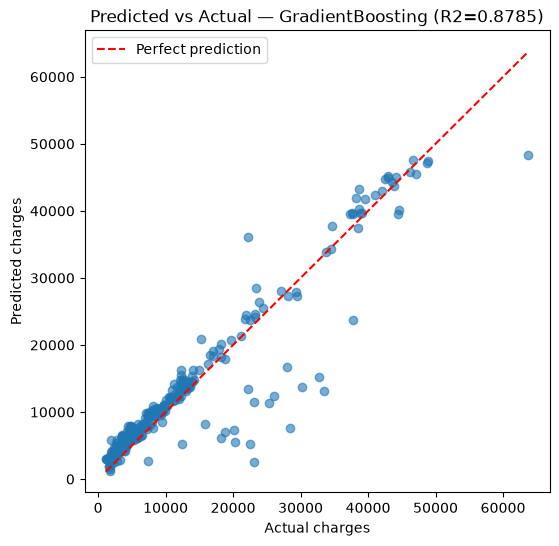

In [7]:
best_name = max(runs, key=lambda n: runs[n]["r2"])
best_run = runs[best_name]
print(f"Best algorithm: {best_name} (R2={best_run['r2']:.4f})")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_run["preds"], alpha=0.6)
lims = [min(y_test.min(), best_run["preds"].min()), max(y_test.max(), best_run["preds"].max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual charges")
plt.ylabel("Predicted charges")
plt.title(f"Predicted vs Actual — {best_name} (R2={best_run['r2']:.4f})")
plt.legend()
plt.savefig("../results/boosting_best_pred_vs_actual.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Record results

In [8]:
rows = [
    {"Dataset": DATASET_NAME, "Task": TASK, "Algorithm": name, "Metric": "R2",
     "Score": round(r["r2"], 4),
     "Params": f"rmse={r['rmse']:.2f}, mae={r['mae']:.2f}"}
    for name, r in runs.items()
]
results_df = pd.DataFrame(rows)
results_df["Best"] = results_df["Algorithm"] == best_name
print(results_df.to_string(index=False))

          Dataset     Task        Algorithm Metric  Score                    Params  Best
insurance_pre.csv Boosting GradientBoosting     R2 0.8785 rmse=4342.91, mae=2424.53  True
insurance_pre.csv Boosting         AdaBoost     R2 0.8270 rmse=5181.86, mae=4253.85 False
insurance_pre.csv Boosting          XGBoost     R2 0.8439 rmse=4922.69, mae=2687.92 False
insurance_pre.csv Boosting         LightGBM     R2 0.8651 rmse=4576.46, mae=2541.42 False


In [9]:
RESULTS_PATH.parent.mkdir(exist_ok=True)
if RESULTS_PATH.exists():
    existing = pd.read_csv(RESULTS_PATH)
    existing = existing[existing["Dataset"] != DATASET_NAME]
    combined = pd.concat([existing, results_df], ignore_index=True)
else:
    combined = results_df
combined.to_csv(RESULTS_PATH, index=False)
print(f"Saved to {RESULTS_PATH.resolve()}")

Saved to /home/ayush/ML-assignment-2/results/results_summary.csv
